# Hi-C Window Comparison Visualization

Visualize and compare Hi-C windows between two samples using Gaussian-smoothed metrics:
- **MSE**: Mean Squared Error between Gaussian-smoothed matrices
- **SSIM**: Structural Similarity Index
- **Spearman**: Spearman correlation between windows
- **EC/IB/SP**: Effective Coverage, Imbalance, Sparsity covariates

## Usage
1. Select a comparison from the dropdown
2. Choose visualization type
3. Explore individual windows or summary plots

In [1]:
import os
import sys
import h5py
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cooler
from matplotlib.colors import LogNorm, Normalize
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')

# Configuration
OUTDIR = "results"
# WORKDIR = "/share/home/xhhuang24/project/PanTE/background_build"
WORKDIR = "/share/home/xhhuang24/project/PanTE/background_pool"
os.chdir(WORKDIR)
print(f"Working directory: {WORKDIR}")

Working directory: /share/home/xhhuang24/project/PanTE/background_pool


In [2]:
# List available comparisons
def list_comparisons():
    """List available comparison names from window_compare directory."""
    compare_dir = os.path.join(WORKDIR, OUTDIR, "window_compare")
    comparisons = []
    if os.path.exists(compare_dir):
        for d in os.listdir(compare_dir):
            metrics_file = os.path.join(compare_dir, d, f"{d}_window_pair_metrics.tsv")
            if os.path.exists(metrics_file):
                comparisons.append(d)
    return sorted(comparisons)

comparisons = list_comparisons()
print(f"Available comparisons ({len(comparisons)}):")
for c in comparisons:
    print(f"  - {c}")

Available comparisons (3):
  - H1398_rep1_vs_H1398_rep2
  - L128_rep1_vs_L128_rep2
  - L134_rep1_vs_L134_rep2


In [10]:
# Configuration
SELECTED_COMPARISON = comparisons[2] if comparisons else None
RESOLUTION = 4000  # 4kb bins

compare_dir = os.path.join(WORKDIR, OUTDIR, "window_compare", SELECTED_COMPARISON)
windows_dir = os.path.join(WORKDIR, OUTDIR, "windows")

print(f"Selected comparison: {SELECTED_COMPARISON}")
print(f"Comparison directory: {compare_dir}")

Selected comparison: L134_rep1_vs_L134_rep2
Comparison directory: /share/home/xhhuang24/project/PanTE/background_pool/results/window_compare/L134_rep1_vs_L134_rep2


In [11]:
# Load comparison data and filter by PASS status
def load_comparison_data(comparison_name):
    """
    Load all metrics for a comparison.
    Filters to keep only windows that PASS in BOTH samples.
    """
    compare_dir = os.path.join(WORKDIR, OUTDIR, "window_compare", comparison_name)
    
    # Load all data
    metrics = pd.read_csv(os.path.join(compare_dir, f"{comparison_name}_window_pair_metrics.tsv"), sep="\t")
    gaussian = pd.read_csv(os.path.join(compare_dir, f"{comparison_name}_gaussian_metrics.tsv"), sep="\t")
    covariates = pd.read_csv(os.path.join(compare_dir, f"{comparison_name}_covariates.tsv"), sep="\t")
    
    # Get sample names
    sample_a = metrics['sample_a'].iloc[0]
    sample_b = metrics['sample_b'].iloc[0]
    
    # Create unique key for joining
    metrics['_key'] = metrics['chrom'] + '_' + metrics['window_id'].astype(str)
    gaussian['_key'] = gaussian['chrom'] + '_' + gaussian['window_id'].astype(str)
    covariates['_key'] = covariates['chrom'] + '_' + covariates['window_id'].astype(str)
    
    # Load QC status for sample A
    print(f"Loading QC status for {sample_a}...")
    qc_status_a = {}
    for chrom in metrics['chrom'].unique():
        qc_file = os.path.join(windows_dir, sample_a, f"{sample_a}__{chrom}_window_qc.tsv")
        if os.path.exists(qc_file):
            qc_df = pd.read_csv(qc_file, sep="\t", index_col=0)
            for _, row in qc_df.iterrows():
                key = f"{chrom}_{row['window_id']}"
                qc_status_a[key] = row['status']
    
    # Load QC status for sample B
    print(f"Loading QC status for {sample_b}...")
    qc_status_b = {}
    for chrom in metrics['chrom'].unique():
        qc_file = os.path.join(windows_dir, sample_b, f"{sample_b}__{chrom}_window_qc.tsv")
        if os.path.exists(qc_file):
            qc_df = pd.read_csv(qc_file, sep="\t", index_col=0)
            for _, row in qc_df.iterrows():
                key = f"{chrom}_{row['window_id']}"
                qc_status_b[key] = row['status']
    
    # Apply filter: keep only windows PASS in both samples
    metrics['status_a'] = metrics['_key'].map(qc_status_a).fillna('UNKNOWN')
    metrics['status_b'] = metrics['_key'].map(qc_status_b).fillna('UNKNOWN')
    
    pass_mask = (metrics['status_a'] == 'PASS') & (metrics['status_b'] == 'PASS')
    pass_keys = set(metrics[pass_mask]['_key'])
    
    n_total = len(metrics)
    n_pass = len(pass_keys)
    print(f"Total window pairs: {n_total}")
    print(f"Both samples PASS: {n_pass} ({100*n_pass/n_total:.1f}%)")
    print(f"Filtered out: {n_total - n_pass}")
    
    # Apply filter to all dataframes
    metrics_filtered = metrics[pass_mask].drop(columns=['_key', 'status_a', 'status_b'])
    gaussian_filtered = gaussian[gaussian['_key'].isin(pass_keys)].drop(columns=['_key'])
    covariates_filtered = covariates[covariates['_key'].isin(pass_keys)].drop(columns=['_key'])
    
    return metrics_filtered, gaussian_filtered, covariates_filtered


metrics, gaussian, covariates = load_comparison_data(SELECTED_COMPARISON)
print(f"\nLoaded {len(metrics)} PASS window pairs")
print(f"\nColumns: {list(metrics.columns)}")


Loading QC status for L134_rep1...
Loading QC status for L134_rep2...
Total window pairs: 59414
Both samples PASS: 59414 (100.0%)
Filtered out: 0

Loaded 59414 PASS window pairs

Columns: ['chrom', 'window_id', 'window_start', 'window_end', 'EC', 'IB', 'SP', 'raw_sum_cpm_a', 'raw_sum_cpm_b', 'nz_frac_a', 'nz_frac_b', 'MSE', 'SSIM', 'Spearman', 'tw_statistic', 'tw_pvalue', 'comparison', 'sample_a', 'sample_b']


In [12]:
# Summary statistics
print("=== Summary Statistics ===")
print(f"\nCovariates:")
print(f"  EC range: [{covariates['EC'].min():.4f}, {covariates['EC'].max():.4f}]")
print(f"  IB range: [{covariates['IB'].min():.4f}, {covariates['IB'].max():.4f}]")
print(f"  SP range: [{covariates['SP'].min():.4f}, {covariates['SP'].max():.4f}]")

print(f"\nGaussian Metrics:")
print(f"  MSE range: [{gaussian['MSE'].min():.4f}, {gaussian['MSE'].max():.4f}]")
print(f"  SSIM range: [{gaussian['SSIM'].min():.4f}, {gaussian['SSIM'].max():.4f}]")
print(f"  Spearman range: [{gaussian['Spearman'].min():.4f}, {gaussian['Spearman'].max():.4f}]")

=== Summary Statistics ===

Covariates:
  EC range: [0.0032, 0.0206]
  IB range: [0.0000, 0.4390]
  SP range: [0.6235, 0.9935]

Gaussian Metrics:
  MSE range: [0.1258, 1.5578]
  SSIM range: [0.2658, 0.9530]
  Spearman range: [0.2542, 0.9564]


## 1. Metric Distributions

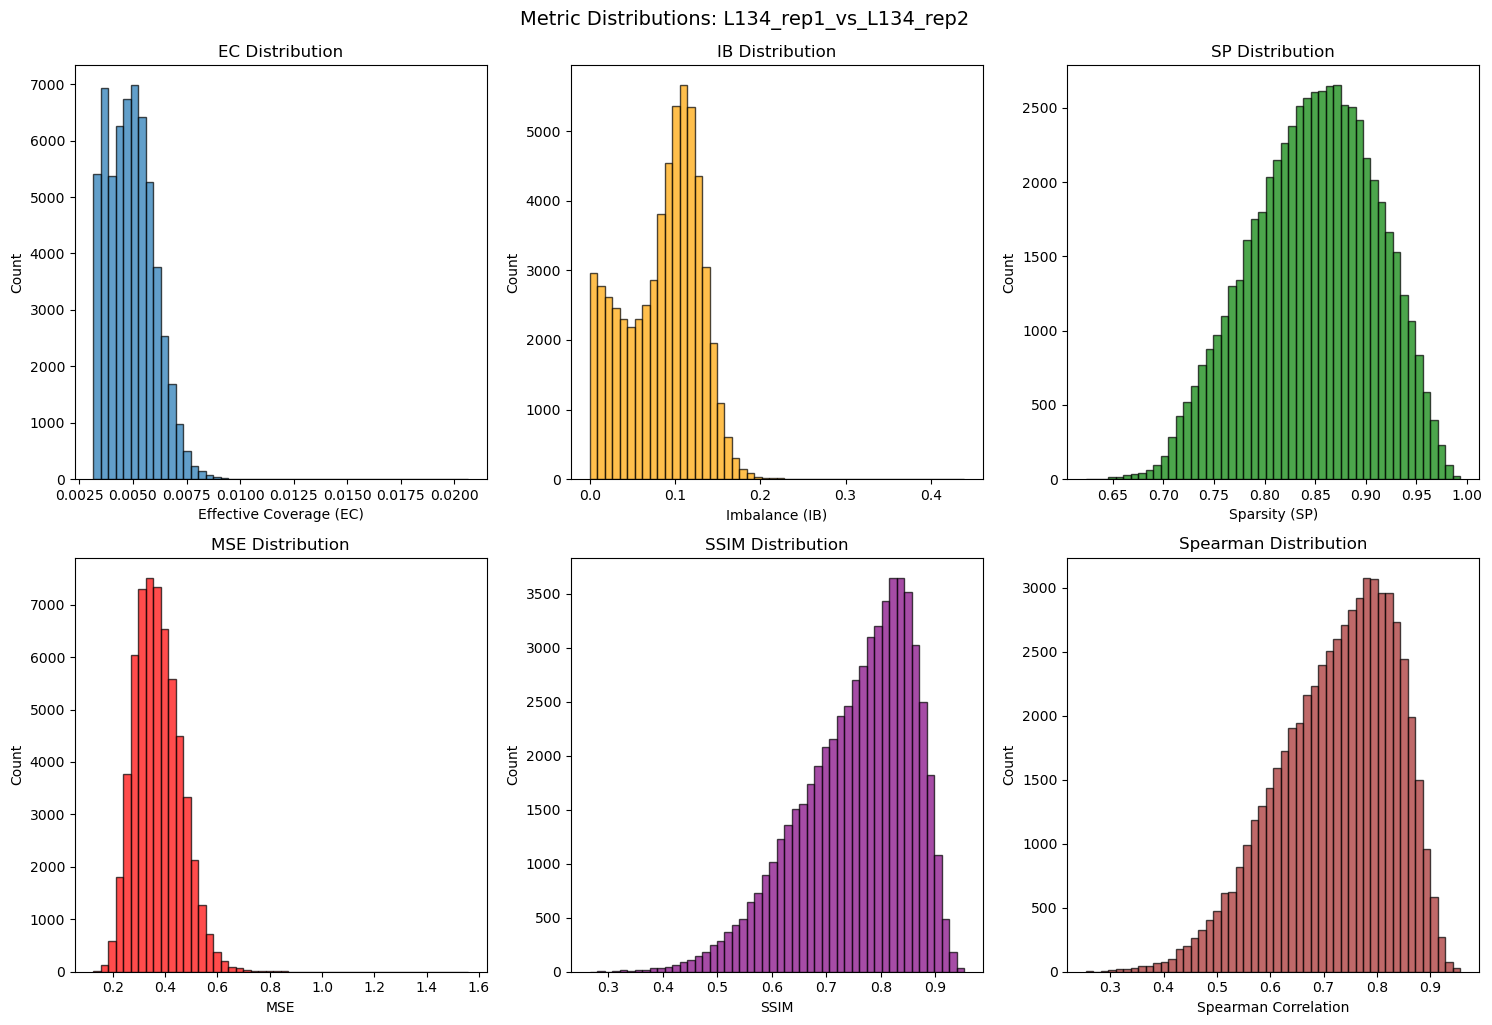

In [13]:
# Plot distribution of comparison metrics
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Covariates
axes[0, 0].hist(covariates['EC'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Effective Coverage (EC)')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_title('EC Distribution')

axes[0, 1].hist(covariates['IB'], bins=50, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].set_xlabel('Imbalance (IB)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title('IB Distribution')

axes[0, 2].hist(covariates['SP'], bins=50, edgecolor='black', alpha=0.7, color='green')
axes[0, 2].set_xlabel('Sparsity (SP)')
axes[0, 2].set_ylabel('Count')
axes[0, 2].set_title('SP Distribution')

# Gaussian metrics
axes[1, 0].hist(gaussian['MSE'], bins=50, edgecolor='black', alpha=0.7, color='red')
axes[1, 0].set_xlabel('MSE')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('MSE Distribution')

axes[1, 1].hist(gaussian['SSIM'], bins=50, edgecolor='black', alpha=0.7, color='purple')
axes[1, 1].set_xlabel('SSIM')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('SSIM Distribution')

axes[1, 2].hist(gaussian['Spearman'], bins=50, edgecolor='black', alpha=0.7, color='brown')
axes[1, 2].set_xlabel('Spearman Correlation')
axes[1, 2].set_ylabel('Count')
axes[1, 2].set_title('Spearman Distribution')

plt.tight_layout()
plt.suptitle(f'Metric Distributions: {SELECTED_COMPARISON}', y=1.02, fontsize=14)
plt.show()

## 2. Scatter Plots: EC vs MSE, SSIM, Spearman

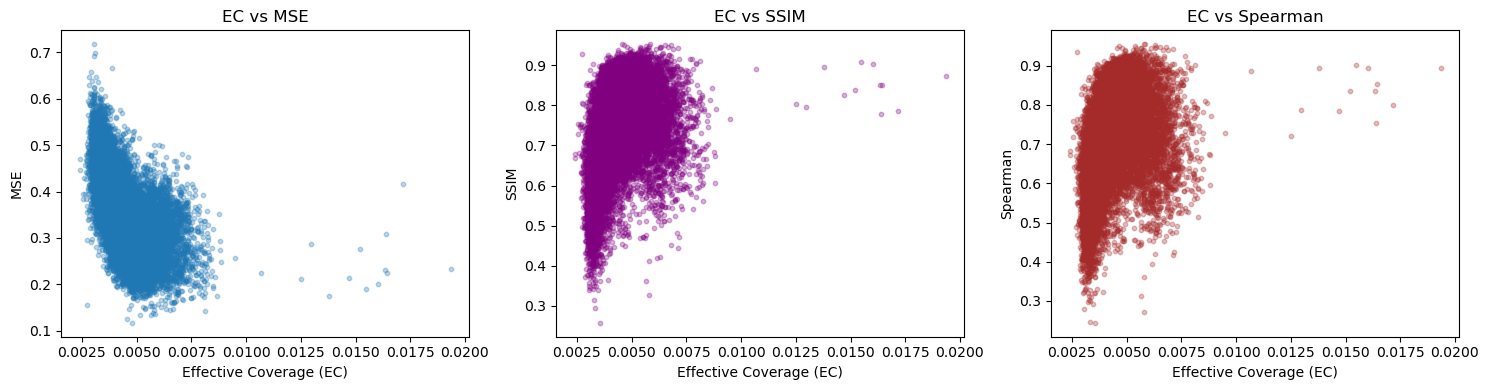

In [7]:
# Scatter plots: EC vs comparison metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(covariates['EC'], gaussian['MSE'], alpha=0.3, s=10)
axes[0].set_xlabel('Effective Coverage (EC)')
axes[0].set_ylabel('MSE')
axes[0].set_title('EC vs MSE')

axes[1].scatter(covariates['EC'], gaussian['SSIM'], alpha=0.3, s=10, color='purple')
axes[1].set_xlabel('Effective Coverage (EC)')
axes[1].set_ylabel('SSIM')
axes[1].set_title('EC vs SSIM')

axes[2].scatter(covariates['EC'], gaussian['Spearman'], alpha=0.3, s=10, color='brown')
axes[2].set_xlabel('Effective Coverage (EC)')
axes[2].set_ylabel('Spearman')
axes[2].set_title('EC vs Spearman')

plt.tight_layout()
plt.show()

## 3. Chromosome-level Summary

In [8]:
# Summary by chromosome
chrom_summary = metrics.groupby('chrom').agg({
    'MSE': ['mean', 'std'],
    'SSIM': ['mean', 'std'],
    'Spearman': ['mean', 'std'],
    'window_id': 'count'
}).round(4)
chrom_summary.columns = ['MSE_mean', 'MSE_std', 'SSIM_mean', 'SSIM_std', 
                         'Spearman_mean', 'Spearman_std', 'n_windows']
chrom_summary = chrom_summary.reset_index()

print("=== Chromosome Summary ===")
chrom_summary

=== Chromosome Summary ===


,chrom,MSE_mean,MSE_std,SSIM_mean,SSIM_std,Spearman_mean,Spearman_std,n_windows
0,HC04_A01,0.3702,0.0896,0.7237,0.1146,0.6961,0.1184,909
1,HC04_A02,0.3830,0.0893,0.6900,0.1296,0.6576,0.1352,1057
2,HC04_A03,0.3752,0.0862,0.7067,0.1249,0.6752,0.1298,1278
3,HC04_A04,0.3805,0.0835,0.6923,0.1299,0.6618,0.1355,946
4,HC04_A05,0.3413,0.0752,0.7680,0.0941,0.7438,0.0993,881
5,HC04_A06,0.3680,0.0889,0.7203,0.1126,0.6892,0.1159,953
6,HC04_A07,0.3449,0.0805,0.7595,0.1023,0.7329,0.1082,928
7,HC04_A08,0.3500,0.0828,0.7497,0.1082,0.7206,0.1121,1015
8,HC04_A09,0.3583,0.0780,0.7414,0.0998,0.7159,0.1052,844
9,HC04_A10,0.3638,0.0853,0.7199,0.1248,0.6910,0.1297,1440


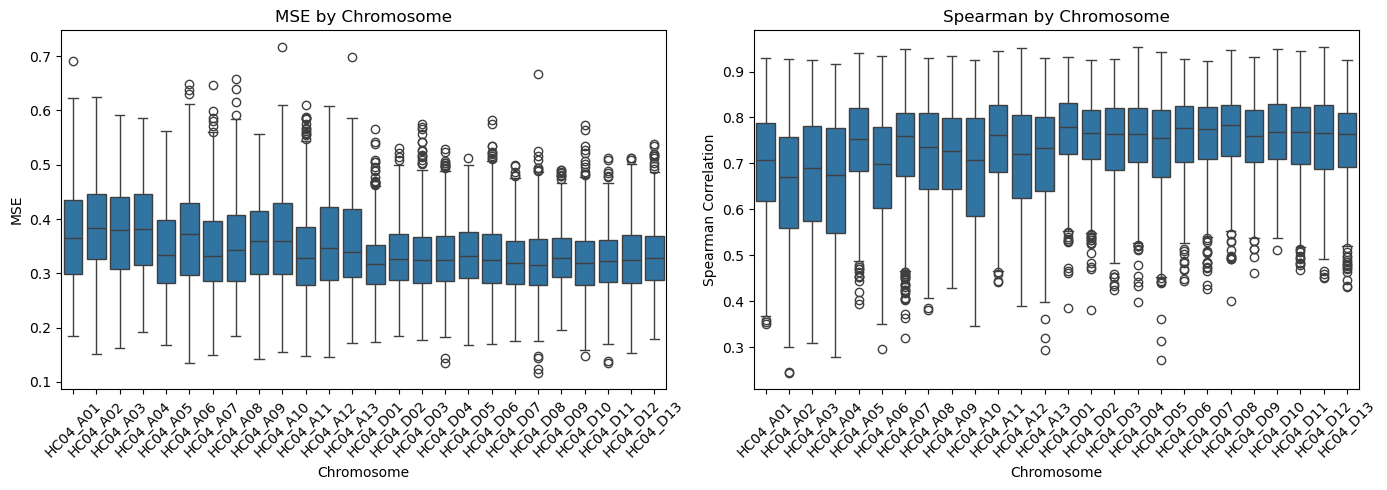

In [9]:
# Plot chromosome-level MSE and Spearman
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MSE by chromosome
chrom_order = sorted(metrics['chrom'].unique())
sns.boxplot(data=metrics, x='chrom', y='MSE', ax=axes[0], order=chrom_order)
axes[0].set_xlabel('Chromosome')
axes[0].set_ylabel('MSE')
axes[0].set_title('MSE by Chromosome')
axes[0].tick_params(axis='x', rotation=45)

# Spearman by chromosome
sns.boxplot(data=metrics, x='chrom', y='Spearman', ax=axes[1], order=chrom_order)
axes[1].set_xlabel('Chromosome')
axes[1].set_ylabel('Spearman Correlation')
axes[1].set_title('Spearman by Chromosome')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 4. Heatmap: Chromosome x Chromosome Comparison

In [10]:
# Create chromosome x chromosome heatmap of mean MSE
chrom_pivot = metrics.pivot_table(
    values='MSE', 
    index='chrom', 
    columns='chrom', 
    aggfunc='mean'
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(chrom_pivot, annot=True, fmt='.4f', cmap='viridis', 
            ax=ax, cbar_kws={'label': 'Mean MSE'})
ax.set_title(f'Chromosome x Chromosome Mean MSE: {SELECTED_COMPARISON}')
plt.tight_layout()
plt.show()

ValueError: Grouper for 'chrom' not 1-dimensional

## 5. Top Differentiated Windows

Identify windows with highest MSE (most different between samples).

In [ ]:
# Find top differentiated windows (highest MSE)
top_n = 10
top_diff = metrics.nlargest(top_n, 'MSE')[['chrom', 'window_start', 'window_end', 
                                          'MSE', 'SSIM', 'Spearman', 
                                          'EC', 'IB', 'SP']]
print(f"=== Top {top_n} Differentiated Windows (by MSE) ===")
top_diff

In [ ]:
# Find most similar windows (lowest MSE)
top_similar = metrics.nsmallest(top_n, 'MSE')[['chrom', 'window_start', 'window_end', 
                                                'MSE', 'SSIM', 'Spearman', 
                                                'EC', 'IB', 'SP']]
print(f"=== Top {top_n} Most Similar Windows (by MSE) ===")
top_similar

## 6. Window Position Visualization

Plot MSE and Spearman along chromosome for a selected chromosome.

In [ ]:
# Select a chromosome for detailed visualization
selected_chrom = sorted(metrics['chrom'].unique())[0]

chrom_data = metrics[metrics['chrom'] == selected_chrom].copy()
chrom_data = chrom_data.sort_values('window_start')

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Plot MSE
axes[0].plot(chrom_data['window_start'] / 1e6, chrom_data['MSE'], 'r-', alpha=0.7)
axes[0].fill_between(chrom_data['window_start'] / 1e6, chrom_data['MSE'], alpha=0.3, color='red')
axes[0].set_ylabel('MSE')
axes[0].set_title(f'MSE along {selected_chrom}')
axes[0].axhline(y=chrom_data['MSE'].mean(), color='black', linestyle='--', label='Mean')
axes[0].legend()

# Plot SSIM
axes[1].plot(chrom_data['window_start'] / 1e6, chrom_data['SSIM'], 'purple', alpha=0.7)
axes[1].fill_between(chrom_data['window_start'] / 1e6, chrom_data['SSIM'], alpha=0.3, color='purple')
axes[1].set_ylabel('SSIM')
axes[1].set_title(f'SSIM along {selected_chrom}')
axes[1].axhline(y=chrom_data['SSIM'].mean(), color='black', linestyle='--', label='Mean')
axes[1].legend()

# Plot Spearman
axes[2].plot(chrom_data['window_start'] / 1e6, chrom_data['Spearman'], 'brown', alpha=0.7)
axes[2].fill_between(chrom_data['window_start'] / 1e6, chrom_data['Spearman'], alpha=0.3, color='brown')
axes[2].set_ylabel('Spearman')
axes[2].set_title(f'Spearman Correlation along {selected_chrom}')
axes[2].axhline(y=chrom_data['Spearman'].mean(), color='black', linestyle='--', label='Mean')
axes[2].legend()

axes[2].set_xlabel(f'Window Start (Mb) on {selected_chrom}')

plt.tight_layout()
plt.show()

## 7. Individual Window Matrix Visualization

Load and display the actual Hi-C matrices for a specific window from both samples.

In [ ]:
# Load window matrices (Gaussian-smoothed)
def load_window_matrices(comparison, sample_a, sample_b, chrom, window_start, window_end):
    """Load Gaussian-smoothed matrices for a window from both samples."""
    
    # Find the window_id from metrics
    window_row = metrics[(metrics['chrom'] == chrom) & 
                         (metrics['window_start'] == window_start)]
    if len(window_row) == 0:
        print(f"Window not found: {chrom}:{window_start}-{window_end}")
        return None, None
    
    window_id = window_row['window_id'].values[0]
    n_bins = window_row['n_bins'].values[0]
    
    # Load Gaussian-smoothed matrices from HDF5
    gauss_a_path = os.path.join(windows_dir, sample_a, f"{sample_a}__{chrom}_gaussian.h5")
    gauss_b_path = os.path.join(windows_dir, sample_b, f"{sample_b}__{chrom}_gaussian.h5")
    
    mat_a = None
    mat_b = None
    
    if os.path.exists(gauss_a_path):
        with h5py.File(gauss_a_path, 'r') as f:
            key = f"{chrom}_{window_id}"
            if key in f:
                mat_a = f[key][()]
    
    if os.path.exists(gauss_b_path):
        with h5py.File(gauss_b_path, 'r') as f:
            key = f"{chrom}_{window_id}"
            if key in f:
                mat_b = f[key][()]
    
    return mat_a, mat_b

# Get sample names from the comparison
sample_a = metrics['sample_a'].iloc[0]
sample_b = metrics['sample_b'].iloc[0]
print(f"Sample A: {sample_a}")
print(f"Sample B: {sample_b}")

In [ ]:
# Visualize a specific window
# Select a window with high MSE (differentiated)
test_window = top_diff.iloc[0]
chrom = test_window['chrom']
window_start = int(test_window['window_start'])
window_end = int(test_window['window_end'])

print(f"Visualizing window: {chrom}:{window_start:,}-{window_end:,}")
print(f"MSE: {test_window['MSE']:.4f}, SSIM: {test_window['SSIM']:.4f}, Spearman: {test_window['Spearman']:.4f}")

mat_a, mat_b = load_window_matrices(SELECTED_COMPARISON, sample_a, sample_b, chrom, window_start, window_end)

if mat_a is not None and mat_b is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Sample A
    im0 = axes[0].imshow(mat_a, cmap='viridis', aspect='equal')
    axes[0].set_title(f'{sample_a}\n{chrom}:{window_start:,}-{window_end:,}')
    plt.colorbar(im0, ax=axes[0], label='Gaussian smoothed')
    
    # Sample B
    im1 = axes[1].imshow(mat_b, cmap='viridis', aspect='equal')
    axes[1].set_title(f'{sample_b}\n{chrom}:{window_start:,}-{window_end:,}')
    plt.colorbar(im1, ax=axes[1], label='Gaussian smoothed')
    
    # Difference (A - B)
    diff = mat_a - mat_b
    vmax = max(abs(diff.min()), abs(diff.max()))
    im2 = axes[2].imshow(diff, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='equal')
    axes[2].set_title(f'Difference (A - B)\nMSE={test_window["MSE"]:.4f}')
    plt.colorbar(im2, ax=axes[2], label='Difference')
    
    plt.tight_layout()
    plt.show()
else:
    print("Could not load matrices. HDF5 files may not exist for this window.")

## 8. Interactive Window Browser

Browse windows along a chromosome by position.

In [ ]:
# Browser settings
BROWSE_CHROM = selected_chrom
BROWSE_START_MB = 0
BROWSE_END_MB = 50  # Show first 50Mb

def plot_browser_windows(chrom, start_mb, end_mb):
    """Plot windows in a genomic region."""
    chrom_data = metrics[
        (metrics['chrom'] == chrom) & 
        (metrics['window_start'] >= start_mb * 1e6) &
        (metrics['window_end'] <= end_mb * 1e6)
    ].sort_values('window_start')
    
    if len(chrom_data) == 0:
        print(f"No windows found in {chrom}:{start_mb}-{end_mb}Mb")
        return
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
    
    x = chrom_data['window_start'] / 1e6
    
    axes[0].scatter(x, chrom_data['MSE'], c=chrom_data['MSE'], cmap='Reds', 
                    s=20, alpha=0.7)
    axes[0].set_ylabel('MSE')
    axes[0].set_title(f'{chrom} {start_mb}-{end_mb}Mb: Windows')
    
    axes[1].scatter(x, chrom_data['SSIM'], c=chrom_data['SSIM'], cmap='Purples', 
                    s=20, alpha=0.7)
    axes[1].set_ylabel('SSIM')
    
    axes[2].scatter(x, chrom_data['Spearman'], c=chrom_data['Spearman'], cmap='Brwn', 
                    s=20, alpha=0.7)
    axes[2].set_ylabel('Spearman')
    axes[2].set_xlabel(f'Position (Mb) on {chrom}')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Showing {len(chrom_data)} windows")

plot_browser_windows(BROWSE_CHROM, BROWSE_START_MB, BROWSE_END_MB)

## 9. Export Results

Export filtered windows based on criteria.

In [ ]:
# Export differentiated windows (MSE > threshold)
MSE_THRESHOLD = metrics['MSE'].quantile(0.9)  # Top 10%
print(f"Exporting windows with MSE > {MSE_THRESHOLD:.4f} (90th percentile)")

diff_windows = metrics[metrics['MSE'] > MSE_THRESHOLD].copy()
diff_windows = diff_windows.sort_values('MSE', ascending=False)

# Add genomic location
diff_windows['genomic_loc'] = diff_windows['chrom'] + ':' + 
                              diff_windows['window_start'].astype(str) + '-' + 
                              diff_windows['window_end'].astype(str)

output_cols = ['comparison', 'genomic_loc', 'chrom', 'window_start', 'window_end',
               'MSE', 'SSIM', 'Spearman', 'EC', 'IB', 'SP',
               'raw_sum_cpm_a', 'raw_sum_cpm_b', 'nz_frac_a', 'nz_frac_b']

diff_export = diff_windows[output_cols]

# Save to CSV
output_path = os.path.join(compare_dir, f"{SELECTED_COMPARISON}_differentiated_windows.tsv")
diff_export.to_csv(output_path, sep='\t', index=False)
print(f"Saved {len(diff_export)} differentiated windows to:")
print(f"  {output_path}")

In [ ]:
# Show top differentiated windows
diff_export.head(20)